In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

# Решение нелинейных уравнений

In [2]:
func = lambda x: np.exp(x) - x ** 3 + 3 * x ** 2 - 2 * x - 3
deriv = lambda x: np.exp(x) - 3 * x ** 2 + 6 * x - 2
phi = lambda x: (np.exp(x) - x ** 3 + 3 * x ** 2 - 3) / 2

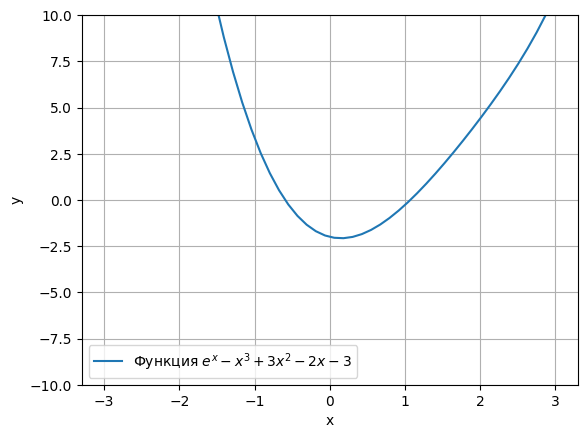

In [3]:
xs = np.linspace(-3, 3, num=50)
ys = func(xs)
plt.plot(xs, ys, label='Функция $e^x - x^3 + 3x^2 - 2x - 3$')
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.ylim((-10, 10))
plt.grid()
plt.show()

Примерное значение ответа лежит в интервале от 0.5 до 1.5, примерно равно единице

## Метод Ньютона

In [4]:
from nm.nonlinear import newton

In [5]:
solution = newton(
    func=func,
    deriv=deriv,
    x0=1.0,
    precision_epsilon=1e-4
)
solution

[WARNING] Условие f(x0)*f''(x0) > 0 не выполнено (значение: -0.765796). Теорема 2.2 не гарантирует монотонную сходимость. Метод может разойтись!


np.float64(1.0738314383248424)

In [6]:
print('Невязка:', func(solution))

Невязка: 1.7426060594516457e-12


## Метод простых итераций

In [7]:
from nm.nonlinear import simple_iteration

In [8]:
solution = simple_iteration(
    func,
    x0=1,
    precision_epsilon=1e-4,
    q='auto',
    lmb="auto",
    interval=[0.5, 1.5],
)
print(solution)
print()

try:
    solution = simple_iteration(
        phi,
        x0=1,
        precision_epsilon=1e-4,
        q='auto',
        interval=[0.5, 1.5],
    )
    print(solution)
except RuntimeError as e:
    print(e)

[INFO] Автоматически вычисленное lmb = 0.301640
[INFO] Автоматически вычисленное q (max|phi'(x)|) = 0.427269
1.0738432290610338

[INFO] Автоматически вычисленное q (max|phi'(x)|) = 3.365845
[WARNING] q >= 1. Формула апостериорной оценки не применима. Используется наивный критерий.
[ERROR] Метод простой итерации не сошелся за отведенное число итераций.


## Зависимость погрешности от числа итераций

In [9]:
from nm.nonlinear import (
    dichotomy,
    newton,
    secant,
    simple_iteration,
)

[WARNING] Условие f(x0)*f''(x0) > 0 не выполнено (значение: -0.765796). Теорема 2.2 не гарантирует монотонную сходимость. Метод может разойтись!
[INFO] Автоматически вычисленное lmb = 0.367062
[WARNING] Условие f(x0)*f''(x0) > 0 не выполнено (значение: -0.765796). Теорема 2.2 не гарантирует монотонную сходимость. Метод может разойтись!
[INFO] Автоматически вычисленное lmb = 0.367062
[WARNING] Условие f(x0)*f''(x0) > 0 не выполнено (значение: -0.765796). Теорема 2.2 не гарантирует монотонную сходимость. Метод может разойтись!
[INFO] Автоматически вычисленное lmb = 0.367062
[WARNING] Условие f(x0)*f''(x0) > 0 не выполнено (значение: -0.765796). Теорема 2.2 не гарантирует монотонную сходимость. Метод может разойтись!
[INFO] Автоматически вычисленное lmb = 0.367062
[WARNING] Условие f(x0)*f''(x0) > 0 не выполнено (значение: -0.765796). Теорема 2.2 не гарантирует монотонную сходимость. Метод может разойтись!
[INFO] Автоматически вычисленное lmb = 0.367062
[WARNING] Условие f(x0)*f''(x0) > 0

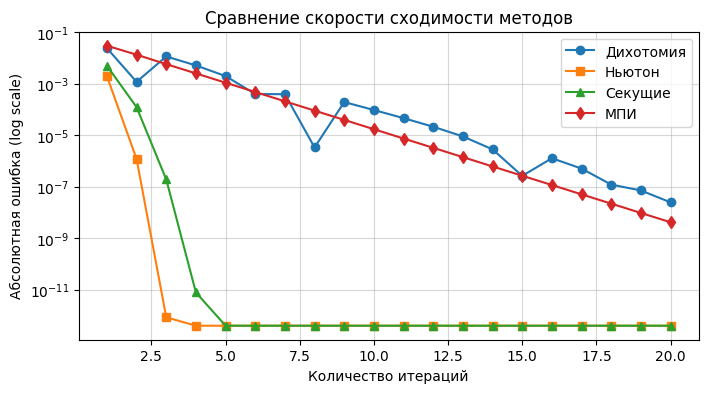

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# "эталонное" решение
x_ethalon = 1.073831438324
iters_range = np.arange(1, 21)

dt_errors = []
nt_errors = []
sc_errors = []
si_errors = []

for n_iters in iters_range:
    # Получаем решения для каждого метода
    dt_sol = dichotomy(func, [0.9, 1.1], max_iter=n_iters)
    nt_sol = newton(func, deriv, x0=1, max_iter=n_iters)
    sc_sol = secant(func, x0=0.9, x1=1.0, max_iter=n_iters)
    si_sol = simple_iteration(func, x0=1, q="auto", lmb="auto", max_iter=n_iters)

    # Вычисляем абсолютную ошибку и добавляем в соответствующие списки
    dt_errors.append(abs(x_ethalon - dt_sol))
    nt_errors.append(abs(x_ethalon - nt_sol))
    sc_errors.append(abs(x_ethalon - sc_sol))
    si_errors.append(abs(x_ethalon - si_sol))

plt.figure(figsize=(8, 4))

plt.plot(iters_range, dt_errors, label='Дихотомия', marker='o')
plt.plot(iters_range, nt_errors, label='Ньютон', marker='s')
plt.plot(iters_range, sc_errors, label='Секущие', marker='^')
plt.plot(iters_range, si_errors, label='МПИ', marker='d')

plt.yscale('log')

plt.title('Сравнение скорости сходимости методов')
plt.xlabel('Количество итераций')
plt.ylabel('Абсолютная ошибка (log scale)')
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.legend()
plt.show()

# Решение систем нелинейных уравнений

In [11]:
funcs = [
    lambda x: x[0] - np.cos(x[1]) - 2,
    lambda x: x[1] - np.sin(x[0]) - 2,
]
phis = [
    lambda x: np.cos(x[1]) + 2,
    lambda x: np.sin(x[0]) + 2,
]

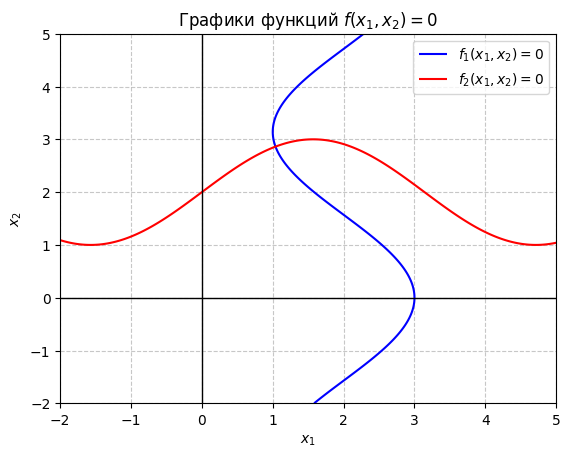

In [12]:
# Создаем сетку значений
x1_range = np.linspace(-2, 5, 400)
x2_range = np.linspace(-2, 5, 400)
X1, X2 = np.meshgrid(x1_range, x2_range)

# Отрисовываем контур для каждой функции, где значение равно 0
CS1 = plt.contour(X1, X2, funcs[0]([X1, X2]), levels=[0], colors='blue')
CS2 = plt.contour(X1, X2, funcs[1]([X1, X2]), levels=[0], colors='red')

# Добавляем легенду
h1, _ = CS1.legend_elements()
h2, _ = CS2.legend_elements()
plt.legend([h1[0], h2[0]], ["$f_1(x_1, x_2) = 0$", "$f_2(x_1, x_2) = 0$"])

# Оформление
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Графики функций $f(x_1, x_2) = 0$')
plt.grid(True, linestyle='--', alpha=0.7)
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)

plt.show()

Итак, решение лежит в интервале $[0.8, 1.2]\times [2.8, 3.2]$

## Метод Ньютона

In [13]:
from nm.nonlinear import newton_system

In [14]:
solution = newton_system(funcs, x0=[1, 3], precision_epsilon=1e-4)
solution

[INFO] Начало итераций. n = 2, x0 = [1. 3.], ||f(x0)|| = 1.588446e-01, det(J(x0)) = 1.076247e+00.
[INFO] Якобиан вычисляется численно (h = 1e-06).
[INFO] Сходимость достигнута на итерации 3. ||dx|| = 2.958e-05 <= eps = 1.000e-04. ||f(x*)|| = 3.249e-10.


array([1.03887749, 2.86183545])

In [15]:
print('Невязка:', [f'{func(solution).item():.14f}' for func in funcs])

Невязка: ['-0.00000000030920', '0.00000000009973']


## Метод простых итераций

In [16]:
from nm.nonlinear import simple_iteration_system

In [17]:
solution = simple_iteration_system(phis, x0=[1, 2], precision_epsilon=1e-4)
solution

[INFO] Автоматически вычисленное q = ||phi'(x0)|| = 0.909297 (численное дифференцирование, h = 1e-06).
[INFO] Условие сходимости выполнено: q = 0.909297 < 1. Скорректированный порог останова по (2.26): ||dx|| < 9.975e-06.
[INFO] Начало итераций. n = 2, x0 = [1. 2.], ||phi(x0) - x0|| = 1.024186e+00.
[INFO] Сходимость достигнута на итерации 13. ||dx|| = 6.040e-06 < порог = 9.975e-06.


array([1.03887912, 2.86183529])

In [18]:
print('Невязка:', [f'{func(solution).item():.14f}' for func in funcs])

Невязка: ['0.00000157992738', '-0.00000098106686']


## Зависимость погрешности от числа итераций

[INFO] Начало итераций. n = 2, x0 = [1.  2.8], ||f(x0)|| = 7.112032e-02, det(J(x0)) = 1.180995e+00.
[INFO] Якобиан вычисляется численно (h = 1e-06).
[INFO] Выполнено 1 итераций (режим фиксированного числа итераций). ||f(x*)|| = 1.890e-03.
[INFO] Начало итераций. n = 2, x0 = [1.  2.8], ||f(x0)|| = 7.112032e-02, det(J(x0)) = 1.180995e+00.
[INFO] Якобиан вычисляется численно (h = 1e-06).
[INFO] Выполнено 2 итераций (режим фиксированного числа итераций). ||f(x*)|| = 1.271e-06.
[INFO] Начало итераций. n = 2, x0 = [1.  2.8], ||f(x0)|| = 7.112032e-02, det(J(x0)) = 1.180995e+00.
[INFO] Якобиан вычисляется численно (h = 1e-06).
[INFO] Выполнено 3 итераций (режим фиксированного числа итераций). ||f(x*)|| = 5.800e-13.
[INFO] Начало итераций. n = 2, x0 = [1.  2.8], ||f(x0)|| = 7.112032e-02, det(J(x0)) = 1.180995e+00.
[INFO] Якобиан вычисляется численно (h = 1e-06).
[INFO] Выполнено 4 итераций (режим фиксированного числа итераций). ||f(x*)|| = 0.000e+00.
[INFO] Начало итераций. n = 2, x0 = [1.  2.8

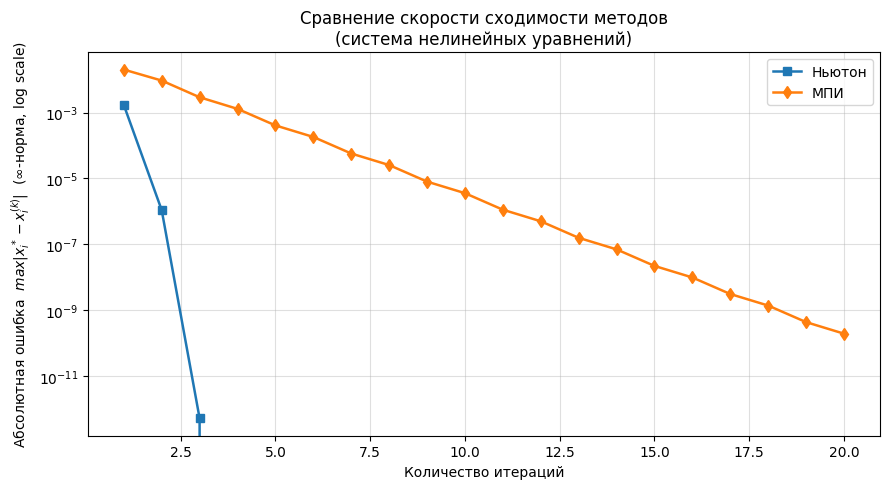

In [ ]:
x_ethalon = np.array([1.038877492420290486, 2.86183544796228520245])

iters_range = np.arange(1, 21)
error = lambda sol: np.linalg.norm(x_ethalon - sol, ord=np.inf)

nt_errors = [error(newton_system(funcs, [1.0, 2.8], max_iter=n)) for n in iters_range]
si_errors = [error(simple_iteration_system(phis, [1.0, 2.8], max_iter=n, q=None)) for n in iters_range]

plt.figure(figsize=(9, 5))
plt.plot(iters_range, nt_errors, label='Ньютон', marker='s', linewidth=1.8)
plt.plot(iters_range, si_errors, label='МПИ',    marker='d', linewidth=1.8)
plt.yscale('log')
plt.title('Сравнение скорости сходимости методов\n(система нелинейных уравнений)')
plt.xlabel('Количество итераций')
plt.ylabel('Абсолютная ошибка  $max|x^*_i − x_i^{(k)}|$  ($\\infty$-норма, log scale)')
plt.grid(True, which='both', ls='-', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()